# 01 — CDR off: speed check

Single encounter, CDR off, dpsi = 90 deg, dcpa = 0; 20, 40 and 60 kt.

20kt: set 10.2889 m/s | ownship 10.2889-10.2889 | intruder 10.2889-10.2889 | max error 1.3e-05 m/s | dcpa 0.0, miss 0.007 m


40kt: set 20.5778 m/s | ownship 20.5778-20.5778 | intruder 20.5778-20.5778 | max error 5.2e-06 m/s | dcpa 0.0, miss 0.003 m


60kt: set 30.8666 m/s | ownship 30.8666-30.8666 | intruder 30.8666-30.8666 | max error 8.9e-06 m/s | dcpa 0.0, miss 0.005 m


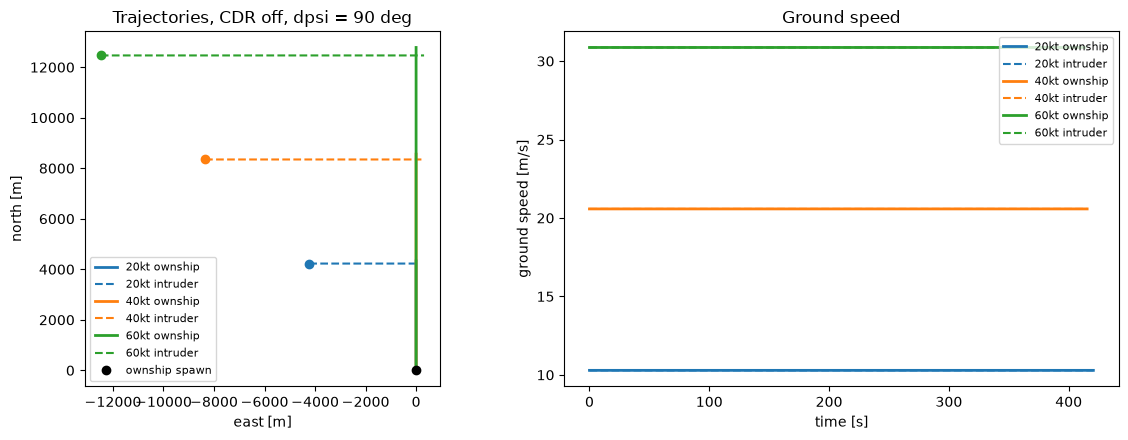

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from blueskycdarr.geo import enu_offset
from sanity import campaign_setup, config, fly, point

DPSI = 90.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for cls, v in config.SPEED_CLASSES.items():
    cfg, models, *_ = campaign_setup(point(cls, DPSI), dcpa=0.0)
    f = fly(cfg, models, seconds=cfg.simulation.t_max, stop_after_cpa=cfg.simulation.done_timeout)  # CDR off
    gs = f["gs"]                                   # columns: ownship, intruder
    east, north = enu_offset(f["lat"][0, 0], f["lon"][0, 0], f["lat"], f["lon"])  # m from ownship spawn
    print(f"{cls}: set {v:.4f} m/s | ownship {gs[:, 0].min():.4f}-{gs[:, 0].max():.4f} | "
          f"intruder {gs[:, 1].min():.4f}-{gs[:, 1].max():.4f} | max error {np.abs(gs - v).max():.1e} m/s | "
          f"dcpa {models.scenario.dcpa}, miss {f['dist'][:, 0].min():.3f} m")
    line, = ax1.plot(east[:, 0], north[:, 0], lw=2, label=f"{cls} ownship")
    ax1.plot(east[:, 1], north[:, 1], lw=1.5, ls="--", color=line.get_color(), label=f"{cls} intruder")
    ax1.plot(east[0, 1], north[0, 1], "o", color=line.get_color())          # intruder spawn
    ax2.plot(f["t"], gs[:, 0], lw=2, color=line.get_color(), label=f"{cls} ownship")
    ax2.plot(f["t"], gs[:, 1], lw=1.5, ls="--", color=line.get_color(), label=f"{cls} intruder")
ax1.plot(0, 0, "ko", label="ownship spawn")
ax1.set_aspect("equal"); ax1.set_xlabel("east [m]"); ax1.set_ylabel("north [m]"); ax1.legend(fontsize=8)
ax1.set_title(f"Trajectories, CDR off, dpsi = {DPSI:.0f} deg")
ax2.set_xlabel("time [s]"); ax2.set_ylabel("ground speed [m/s]"); ax2.legend(fontsize=8)
ax2.set_title("Ground speed")
plt.tight_layout()
plt.show()